# Getting started with pyanimalprocessing: from images to grid-level quantities

<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 50%, #0f3460 100%); color: white; padding: 1.2em 1.8em; border-radius: 10px; margin-bottom: 1em;">

<p style="margin: 0 0 0.2em 0; font-weight: 300; font-size: 0.95em; letter-spacing: 0.05em; opacity: 0.85;">BELLAICHE LAB — Institut Curie</p>
<p style="margin: 0; font-size: 0.82em; opacity: 0.7;">Adrien Leroy, Eric van Leen, Maria Balakireva, Lale Alpar, Fabian Gärtner, Rémi Pigache, Isabelle Gaugué, Stéphane Pelletier, Mehdi Ech-Chouini, Julien Delpierre, Stéphane Rigaud, Floris Bosveld, Lorette Noiret, Yohanns Bellaïche</p>
<p style="margin: 0.1em 0 0 0; font-size: 0.75em; opacity: 0.5;">August 2026</p>

</div>

`pyanimalprocessing` is the Python half of [AnimalProcessing](https://github.com/BellaicheLab/AnimalProcessing), the tissue-morphogenesis engine used in [Leroy, van Leen et al., Cell Reports (2026)](https://doi.org/10.5281/zenodo.19633285). Everything it does revolves around one object: an **animal**, a zarr store holding one specimen and every quantity derived from it.

This notebook walks the **native Python route** end to end on a segmented crop of one of the paper's notum movies, shipped with the repository. We will learn how to:

1. **Create an animal store** from raw images and label masks (`instantiate_animal`)
2. **Measure single-cell properties** with the regionprops engine (`analyze_labels`) and render them with `plot_property`
3. **Register the animal and build a spatial grid** (`generate_common_grid`)
4. **Average cell measurements onto the grid** (`average_over_space`), here the mean cell area per box
5. **Average over time** into a standard backup (`average_over_time`) and **display it** with `read_property` and `plot_property`

The same calls scale unchanged to full movies and cohorts: [02_build_an_expression_atlas](02_build_an_expression_atlas.ipynb) applies them to build a gene-expression atlas, and the [morphodomains notebooks](https://github.com/BellaicheLab/morphodomains) use the resulting stores for the paper's analyses.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import zarr
import napari
import imageio.v3 as iio
import matplotlib.pyplot as plt
from IPython.display import Image

from pyanimalprocessing.preprocessing import instantiate_animal
from pyanimalprocessing.analyze_labels import analyze_labels
from pyanimalprocessing.rescaling.registration import generate_common_grid
from pyanimalprocessing.average_over_space import average_over_space
from pyanimalprocessing.average_over_time import average_over_time
from pyanimalprocessing.plotting import read_property, plot_property

# A 700 x 700 px crop (113 x 113 um, ~680 cells) of movie 210507_vi_pupa1:
# 5 frames of the E-cadherin channel and their label masks, starting at 21h58 APF
DATA = Path("data") / "210507_subset"

# Working folder for the store we are about to build (gitignored)
WORK = Path("_work") / "python_route_basics"
WORK.mkdir(parents=True, exist_ok=True)


def show_gif(name, frames, duration=600):
    """Crop napari screenshots to their content and embed them as a looping GIF."""
    frames = [f[..., :3] for f in frames]
    keep = np.argwhere(np.stack(frames).sum(axis=(0, 3)) > 0)
    (y0, x0), (y1, x1) = keep.min(0), keep.max(0) + 1
    iio.imwrite(WORK / name, [f[y0:y1, x0:x1] for f in frames], duration=duration, loop=0)
    return Image(filename=WORK / name)

## 2. Creating an animal store

`instantiate_animal` ingests raw images and label masks from arrays, single files or folders, the order string describing the axes. It creates the `IMAGE` and `CELL` groups of a fresh zarr store, together with the acquisition metadata: pixel size (`scaling`, µm/px), frame interval (`dt`, minutes) and `temperature`.

Timing attributes anchor the movie in **developmental time**: `time_ref` is the developmental time of frame `frame_ref`, and every later step converts frames to hours-APF through them. Here the first frame of the crop was acquired at 21h58 APF.

In [2]:
animal = instantiate_animal(
    output_zarr=str(WORK / "demo_animal.zarr"),
    raw_image_2d=str(DATA / "raw"), raw_image_2d_order="ct(yx)",
    labels_2d=str(DATA / "label"), labels_2d_order="t(yx)",
    channel_names=["ECad"],
    scaling=0.161, dt=5.0, temperature=29.0, overwrite=True,
)
animal.attrs["time_ref"] = "21h58"
animal.attrs["frame_ref"] = 0

print("raw:   ", animal.IMAGE.D2.raw.shape, " (t, c, y, x)")
print("labels:", animal.IMAGE.D2.label.shape)

raw:    (5, 1, 700, 700)  (t, c, y, x)
labels: (5, 700, 700)


The raw channel and the label masks, straight from the store. Left the ECad channel, right the segmentation drawn as one contour per cell. The GIF loops over the five frames:

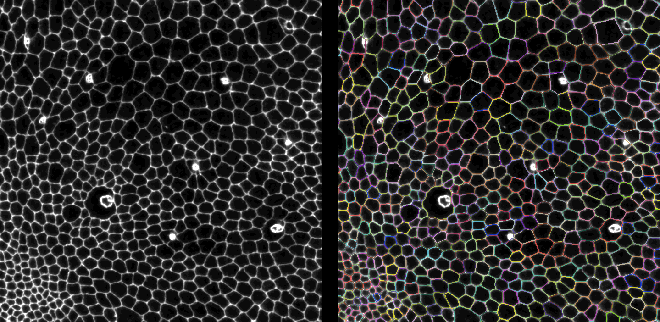

In [3]:
viewer = napari.Viewer()
viewer.add_image(animal.IMAGE.D2.raw, channel_axis=1, name=["ECad"], contrast_limits=[[97, 120]])
cells = viewer.add_labels(np.asarray(animal.IMAGE.D2.label), name="cells")
cells.contour = 2
viewer.reset_view()

frames = []
for f in range(animal.IMAGE.D2.raw.shape[0]):
    viewer.dims.set_current_step(0, f)
    cells.visible = False
    raw_shot = viewer.screenshot(scale=1)
    cells.visible = True
    frames.append(np.hstack([raw_shot, viewer.screenshot(scale=1)]))
viewer.close()
show_gif("raw_and_segmentation.gif", frames)

## 3. Measuring single-cell properties

`analyze_labels` runs a regionprops pass per frame and writes one array per property into `CELL/D2/`. Beyond the skimage properties (`area`, `eccentricity`, ...) it offers custom ones such as cortical intensities, polarity and Fourier modes. `discover_properties()` prints the full catalogue.

In [4]:
analyze_labels(
    [animal], analysis_type="cell",
    properties=["area", "centroid", "coords", "contours", "eccentricity"],
    dimension="D2",
)
print("CELL/D2:", list(animal.CELL.D2.array_keys()))

Analyzing frames:   0%|          | 0/5 [00:00<?, ?it/s]

Analyzing frames:  20%|██        | 1/5 [00:01<00:05,  1.38s/it]

Analyzing frames:  60%|██████    | 3/5 [00:01<00:00,  2.33it/s]

Analyzing frames: 100%|██████████| 5/5 [00:01<00:00,  3.03it/s]

CELL/D2: ['area', 'centroid', 'contours', 'coords', 'eccentricity']


**Optional:** per-cell visualisation. `plot_property` is the single renderer for every measurement in the store, and the *origins* you pass decide the representation. The cell **centroids** give one scaled marker per cell (left), the pixel **coords** paint every cell with its value (right):

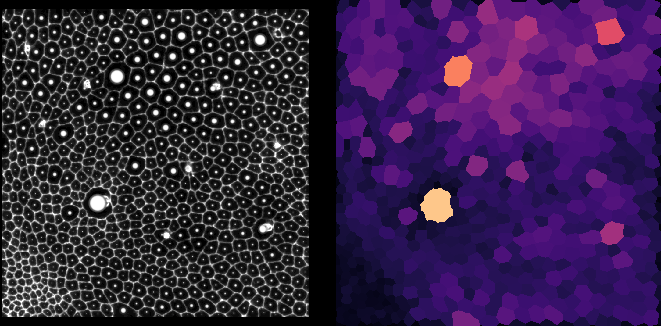

In [5]:
v_centroid = napari.Viewer()
v_centroid.add_image(animal.IMAGE.D2.raw[:, 0], name="ECad", colormap="gray",
                     contrast_limits=[97, 120])
plot_property(property_data=animal.CELL.D2.area, property_origin=animal.CELL.D2.centroid,
              property_name="area", viewer=v_centroid, scalar_scale=0.01)
v_centroid.reset_view()

v_coords = napari.Viewer()
plot_property(property_data=animal.CELL.D2.area, property_origin=animal.CELL.D2["coords"],
              property_name="area", viewer=v_coords)
areas = np.concatenate(list(animal.CELL.D2.area[:, 0]))
v_coords.layers["area"].colormap = "magma"
v_coords.layers["area"].contrast_limits = [0, np.percentile(areas, 99)]
v_coords.reset_view()

frames = []
for f in range(5):
    v_centroid.dims.set_current_step(0, f)
    v_coords.dims.set_current_step(0, f)
    frames.append(np.hstack([v_centroid.screenshot(scale=1), v_coords.screenshot(scale=1)]))
v_centroid.close()
v_coords.close()
show_gif("cell_area.gif", frames)

## 4. Registering the animal and building a grid

Cross-animal comparison needs a common frame: each animal carries a **space registration** (clicked landmarks), and `generate_common_grid` fits an affine transform from them and tiles a grid of overlapping boxes over the tissue.

On real data the landmarks are clicked interactively with `space_registrate(animal)`, the napari tool shown in [02_build_an_expression_atlas](02_build_an_expression_atlas.ipynb); the [space registration guide](../docs/guides/space_registration.md) covers the anatomy. Here we register the animal onto itself by writing four corner landmarks programmatically:

In [6]:
reg = animal.require_group("SPACE_REGISTRATION").require_group("default")
reg.create_dataset("landmarks", overwrite=True,
                   data=np.array([[0.0, 0, 0], [0.0, 0, 699], [0.0, 699, 0], [0.0, 699, 699]]))
reg.create_dataset("lines", data=np.array([]), overwrite=True)
reg.attrs["angle"] = None

# 10 um boxes with 50% overlap on a ~113 um field -> a 23 x 23 grid
generate_common_grid([animal], boxsize=[10, 10], overlap=0.5)

gp = animal.GRID.EULERIAN.GRID_PROPERTIES
print("grid:", gp.X.shape, "boxes   area_ratios:", gp.area_ratios.shape)

Generating Grids objects and rescaling:   0%|          | 0/1 [00:00<?, ?animal/s]

Generating Grids objects and rescaling: 100%|██████████| 1/1 [00:00<00:00, 101.49animal/s]

  0%|          | 0/5 [00:00<?, ?it/s]

 40%|████      | 2/5 [00:00<00:00, 18.33it/s]

100%|██████████| 5/5 [00:00<00:00, 20.44it/s]

100%|██████████| 5/5 [00:00<00:00, 20.13it/s]

Time taken for demo_animal.zarr: 0.6328749656677246 seconds
grid: (23, 23) boxes   area_ratios: (5, 1, 23, 23, 1)


## 5. Cell area at the grid level

`average_over_space` maps per-cell measurements onto the grid through polygon intersection: each box receives the weighted mean of the cells it overlaps (`mean_per_cell`), plus a `cell_number` count. Results land in `GRID/EULERIAN/CELL/D2/`.

Processing animals:   0%|          | 0/1 [00:00<?, ?it/s]

Computing sparse matrices:   0%|          | 0/5 [00:00<?, ?it/s]

Computing sparse matrices:  20%|██        | 1/5 [00:00<00:02,  1.93it/s]

Computing sparse matrices:  80%|████████  | 4/5 [00:00<00:00,  7.76it/s]

Computing sparse matrices: 100%|██████████| 5/5 [00:00<00:00,  7.21it/s]

Aggregating over space:   0%|          | 0/5 [00:00<?, ?it/s]

Aggregating over space:   0%|          | 0/5 [00:00<?, ?it/s]

Processing animals: 100%|██████████| 1/1 [00:00<00:00,  1.11it/s]

Processing animals: 100%|██████████| 1/1 [00:00<00:00,  1.11it/s]

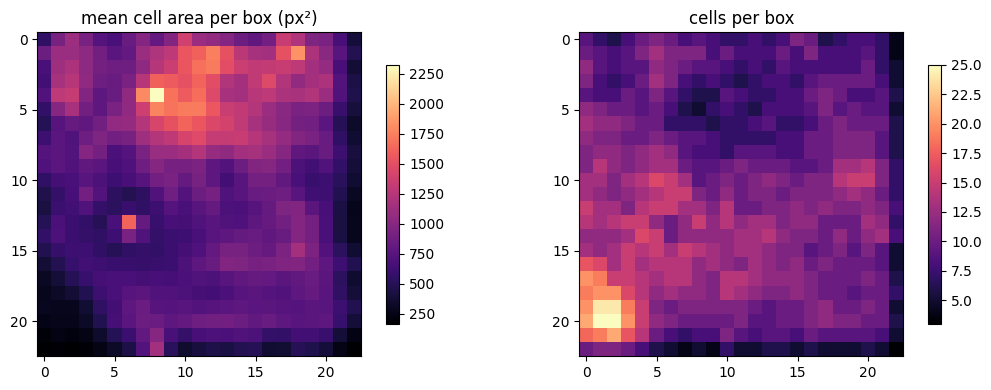

In [7]:
average_over_space(
    [animal], ["area", "eccentricity"],
    global_spatial_type="eulerian", local_spatial_type="cell", dimension="D2",
)

area_grid = np.asarray(animal["GRID/EULERIAN/CELL/D2/area_mean_per_cell"][0, 0, :, :, 0], float)
n_cells   = np.asarray(animal["GRID/EULERIAN/CELL/D2/cell_number"][0, 0, :, :, 0], float)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# grid arrays are indexed (x, y), transpose to display in image orientation
for ax, m, title in [(axes[0], area_grid.T, "mean cell area per box (px²)"),
                     (axes[1], n_cells.T, "cells per box")]:
    im = ax.imshow(m, cmap="magma")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

## 6. Averaging over time and displaying the result

`average_over_time` collapses the movie into developmental-time windows and writes a standard **backup** under `TIME_AVERAGE/<grid>/<type>/D2/<name>`, the same structure the MATLAB pipeline produces, which is what makes the two routes interchangeable downstream. Here the five frames fall into a single 25-minute window.

One reader serves every backup, native or converted: `read_property` returns the render-ready arrays (data, origins, and an affine placing each window at its developmental time) and `plot_property` draws them in napari. Below, the movie plays under its frozen time-average:

In [8]:
average_over_time(
    [animal], ["area_mean_per_cell"],
    time_start="21h58", time_stop="22h03", time_window="00h25", time_step=5,
    grid_type="eulerian", averaged_type="cell", dimension="D2",
)
backup = animal["TIME_AVERAGE/EULERIAN/CELL/D2/default"]
print("backup:", list(backup.array_keys()))

backup: ['area_mean_per_cell', 'frame_array', 'time_array', 'weights']


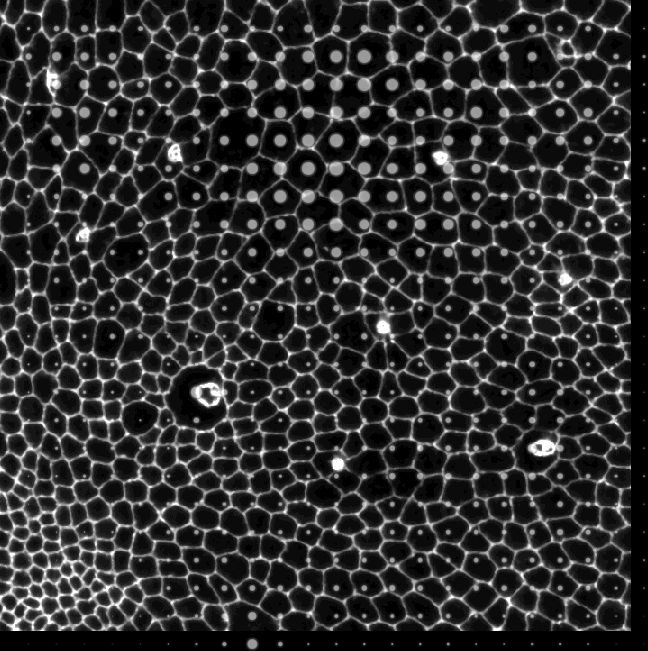

In [9]:
bundle = read_property(backup, "area_mean_per_cell")

viewer = napari.Viewer()
ecad = viewer.add_image(np.asarray(animal.IMAGE.D2.raw[0, 0]), name="ECad", colormap="gray",
                        contrast_limits=[97, 120])
plot_property(**bundle, viewer=viewer, scalar_scale=0.01, scalar_kwargs={"opacity": 0.6})
viewer.reset_view()
viewer.dims.set_current_step(0, 0)

frames = []
for f in range(5):
    ecad.data = np.asarray(animal.IMAGE.D2.raw[f, 0])
    frames.append(viewer.screenshot(scale=2))
viewer.close()
show_gif("time_average.gif", frames)

## 7. The store we built

Every step wrote into the same animal. This is the one nested schema all AnimalProcessing tools read and write:

In [10]:
print(animal.tree())

/
 ├── CELL
 │   ├── D2
 │   │   ├── area (5, 1) object
 │   │   ├── centroid (5, 1) object
 │   │   ├── contours (5,) object
 │   │   ├── coords (5,) object
 │   │   └── eccentricity (5, 1) object
 │   └── D3
 ├── GRID
 │   └── EULERIAN
 │       ├── CELL
 │       │   └── D2
 │       │       ├── area_mean_per_cell (5, 1, 23, 23, 1) float64
 │       │       ├── cell_number (5, 1, 23, 23, 1) int32
 │       │       └── eccentricity_mean_per_cell (5, 1, 23, 23, 1) float64
 │       ├── D2
 │       ├── D3
 │       └── GRID_PROPERTIES
 │           ├── X (23, 23) float64
 │           ├── Y (23, 23) float64
 │           ├── area_ratios (5, 1, 23, 23, 1) float16
 │           ├── box_corners (23, 23, 4, 2) float64
 │           ├── centroids (23, 23, 2) float64
 │           ├── grid_numbers (5, 1, 23, 23, 1) uint16
 │           ├── lagrangian_grid (5, 23, 23) object
 │           ├── mask_positions (23, 23) object
 │           ├── reference_landmarks (4, 2) float64
 │           └── target_landmarks

## Where to go next

- [Using pyanimalprocessing](../docs/guides/python_route.md): the same route in guide form, including how MATLAB results enter through `zarrify_SAP` / `zarrify_MAP`
- [02_build_an_expression_atlas](02_build_an_expression_atlas.ipynb): the same machinery applied to fixed stained samples, ten genes at a time
- The API reference in the rendered documentation covers every function used here